# Transformación del histograma — Versión 3: intervalo mínimo por porcentaje

Esta versión modifica la selección del rango dinámico. En lugar de usar simplemente el primer y último nivel no vacío, encuentra **el intervalo más corto que contiene al menos el porcentaje elegido de los píxeles originales**.

Criterios de desempate:
1. Menor longitud del intervalo.
2. Si hay la misma longitud, mayor número de píxeles dentro del intervalo.
3. Si aún hay empate, menor intensidad inicial.

Después se aproxima el histograma únicamente en ese intervalo; se transforma la función con cuatro parámetros y se reasignan los píxeles por orden de intensidad.

El intervalo determina qué tramo aproximamos, pero **no elimina píxeles de la imagen**. Los píxeles que queden fuera del intervalo seleccionado siguen participando en la reasignación ordenada.

## 1. Importar bibliotecas y cargar la imagen

Saving Imagen (40).jpg to Imagen (40).jpg
Dimensiones: (2336, 3504)
Total de píxeles: 8185344
Intensidad mínima observada: 73
Intensidad máxima observada: 255
Imagen original: A color


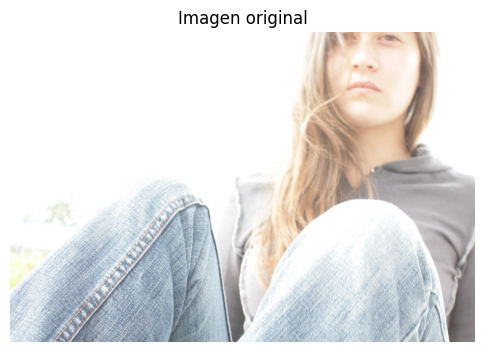

In [113]:
# %% CELDA 1 — CARGAR IMAGEN Y CONSERVAR EL ORIGINAL

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from PIL import Image
from scipy.interpolate import PchipInterpolator
from IPython.display import display

try:
    from google.colab import files

    archivos_subidos = files.upload()

    if not archivos_subidos:
        raise ValueError("No se seleccionó ninguna imagen.")

    ruta_imagen = next(iter(archivos_subidos))

except ImportError:
    ruta_imagen = "imagen.jpg"  # Cambiar si ejecutas fuera de Colab.

# Conservar la imagen original en RGB.
imagen_rgb_original = np.asarray(
    Image.open(ruta_imagen).convert("RGB"),
    dtype=np.uint8
)

# Detectar si la imagen contiene información de color.
es_color = np.any(
    np.max(imagen_rgb_original, axis=2)
    != np.min(imagen_rgb_original, axis=2)
)

# Crear la imagen en escala de grises para los cálculos del modelo.
imagen = np.asarray(
    Image.fromarray(imagen_rgb_original).convert("L"),
    dtype=np.uint8
)

print("Dimensiones:", imagen.shape)
print("Total de píxeles:", imagen.size)
print("Intensidad mínima observada:", int(imagen.min()))
print("Intensidad máxima observada:", int(imagen.max()))
print("Imagen original:", "A color" if es_color else "Escala de grises")

# Mostrar la imagen de entrada tal como es originalmente.
plt.figure(figsize=(6, 6))

if es_color:
    plt.imshow(imagen_rgb_original)
else:
    plt.imshow(imagen, cmap="gray", vmin=0, vmax=255)

plt.title("Imagen original")
plt.axis("off")
plt.show()

## 2. Calcular histograma, CDF y métricas originales

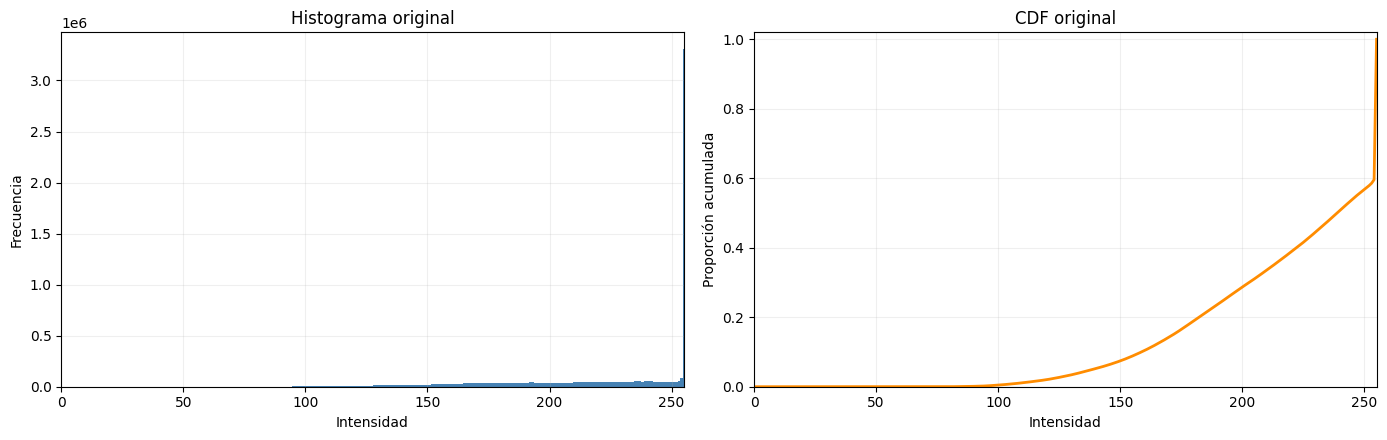

,Original
Media,221.2399
Desviación estándar,40.5510
Mínimo,73.0000
Máximo,255.0000
Rango dinámico,182.0000
Rango P1-P99,146.0000
Entropía (bits),5.2040
Píxeles en 0 (%),0.0000
Píxeles en 255 (%),40.3938


In [114]:
niveles = np.arange(256)
histograma = np.bincount(imagen.ravel(), minlength=256).astype(np.int64)
cdf_original = np.cumsum(histograma) / imagen.size

def calcular_metricas(img):
    img = np.asarray(img, dtype=np.uint8)
    hist = np.bincount(img.ravel(), minlength=256)
    probabilidades = hist / img.size
    probabilidades = probabilidades[probabilidades > 0]
    entropia = -np.sum(probabilidades * np.log2(probabilidades))
    p1, p99 = np.percentile(img, [1, 99])
    return {
        "Media": float(np.mean(img)),
        "Desviación estándar": float(np.std(img)),
        "Mínimo": int(img.min()),
        "Máximo": int(img.max()),
        "Rango dinámico": int(img.max() - img.min()),
        "Rango P1-P99": float(p99 - p1),
        "Entropía (bits)": float(entropia),
        "Píxeles en 0 (%)": float(100 * np.mean(img == 0)),
        "Píxeles en 255 (%)": float(100 * np.mean(img == 255)),
    }

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
ejes[0].bar(niveles, histograma, width=1.0, color="steelblue")
ejes[0].set(title="Histograma original", xlabel="Intensidad", ylabel="Frecuencia", xlim=(0,255))
ejes[0].grid(alpha=0.2)
ejes[1].plot(niveles, cdf_original, color="darkorange", linewidth=2)
ejes[1].set(title="CDF original", xlabel="Intensidad", ylabel="Proporción acumulada", xlim=(0,255), ylim=(0,1.02))
ejes[1].grid(alpha=0.2)
plt.tight_layout()
plt.show()

display(pd.DataFrame([calcular_metricas(imagen)], index=["Original"]).T.round(4))

## 3. Encontrar el intervalo mínimo que contiene el porcentaje elegido

Cambia `PORCENTAJE_CONSERVADO` para experimentar. El algoritmo trabaja directamente con el histograma discreto y busca el intervalo de menor amplitud que contiene al menos esa proporción de píxeles.

El criterio se calcula sobre píxeles reales, no sobre el área de la aproximación. Así, la selección del rango no depende de si después se utiliza PCHIP, interpolación lineal o Fourier.

Porcentaje solicitado: 98.500%
Píxeles requeridos: 8,062,564 de 8,185,344
Intervalo mínimo seleccionado: [115, 255] (ancho 141)
Píxeles dentro: 8,064,602 (98.52490%)
Píxeles fuera: 120,742


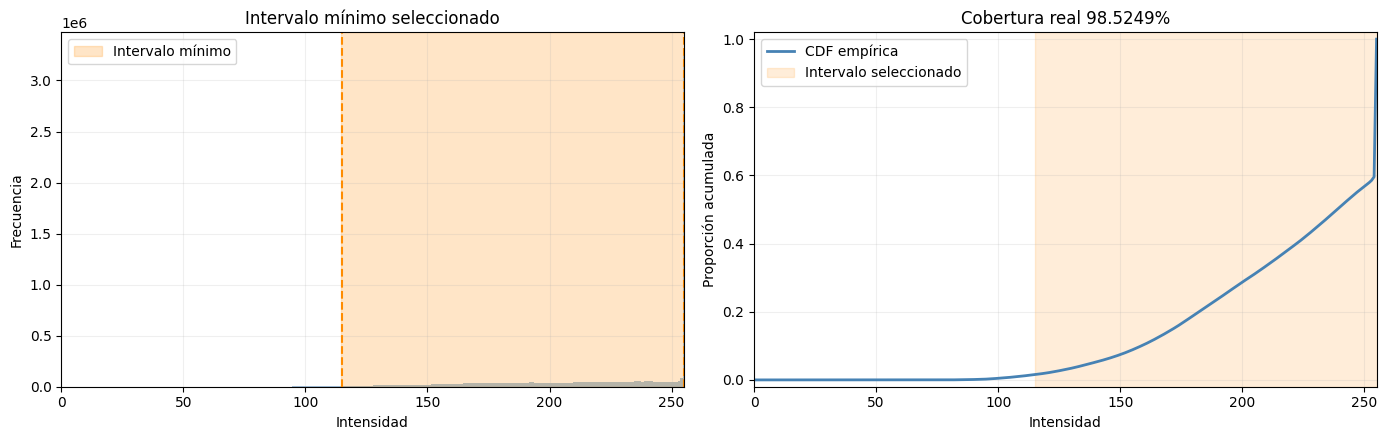

In [115]:
def encontrar_intervalo_minimo(hist, porcentaje):
    """Intervalo más corto que contiene el porcentaje solicitado.

    Desempates: (1) menor ancho, (2) mayor cantidad de píxeles,
    (3) menor intensidad inicial.
    Devuelve: r_min, r_max, pixeles_dentro, total, pixeles_requeridos.
    """
    h = np.asarray(hist, dtype=np.int64).ravel()
    if h.size != 256:
        raise ValueError("El histograma debe tener 256 frecuencias.")
    if np.any(h < 0):
        raise ValueError("Las frecuencias no pueden ser negativas.")
    if not (0 < float(porcentaje) <= 100):
        raise ValueError("El porcentaje debe ser mayor que 0 y como máximo 100.")
    total = int(h.sum())
    if total <= 0:
        raise ValueError("El histograma está vacío.")

    pixeles_requeridos = int(math.ceil(total * float(porcentaje) / 100.0))
    prefijos = np.concatenate(([0], np.cumsum(h, dtype=np.int64)))
    candidatos = []

    # Para cada inicio, encontrar el primer final que alcanza el objetivo.
    # Un final posterior sería un intervalo más ancho para ese mismo inicio.
    for inicio in range(256):
        umbral_prefijo = int(prefijos[inicio]) + pixeles_requeridos
        if umbral_prefijo > total:
            continue
        final_exclusivo = int(np.searchsorted(prefijos, umbral_prefijo, side="left"))
        final = final_exclusivo - 1
        if final < inicio or final > 255:
            continue
        conteo = int(prefijos[final + 1] - prefijos[inicio])
        ancho = final - inicio + 1
        # min() aplica el orden: ancho ascendente, conteo descendente, inicio ascendente.
        candidatos.append((ancho, -conteo, inicio, final, conteo))

    if not candidatos:
        raise RuntimeError("No se encontró un intervalo válido.")
    ancho, conteo_negativo, r_min, r_max, pixeles_dentro = min(candidatos)
    return int(r_min), int(r_max), int(pixeles_dentro), total, int(pixeles_requeridos)

PORCENTAJE_CONSERVADO = 98.5  # Porcentaje mínimo de píxeles dentro del intervalo.
r_min, r_max, pixeles_dentro, total_pixeles, pixeles_requeridos = encontrar_intervalo_minimo(
    histograma, PORCENTAJE_CONSERVADO
)
rango_dinamico = r_max - r_min + 1
porcentaje_real = 100 * pixeles_dentro / total_pixeles
pixeles_fuera = total_pixeles - pixeles_dentro

print(f"Porcentaje solicitado: {PORCENTAJE_CONSERVADO:.3f}%")
print(f"Píxeles requeridos: {pixeles_requeridos:,} de {total_pixeles:,}")
print(f"Intervalo mínimo seleccionado: [{r_min}, {r_max}] (ancho {rango_dinamico})")
print(f"Píxeles dentro: {pixeles_dentro:,} ({porcentaje_real:.5f}%)")
print(f"Píxeles fuera: {pixeles_fuera:,}")

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
ejes[0].bar(niveles, histograma, width=1.0, alpha=0.5, color="steelblue")
ejes[0].axvspan(r_min - 0.5, r_max + 0.5, color="darkorange", alpha=0.22, label="Intervalo mínimo")
ejes[0].axvline(r_min, color="darkorange", linestyle="--")
ejes[0].axvline(r_max, color="darkorange", linestyle="--")
ejes[0].set(title="Intervalo mínimo seleccionado", xlabel="Intensidad", ylabel="Frecuencia", xlim=(0,255))
ejes[0].grid(alpha=0.2)
ejes[0].legend()
ejes[1].plot(niveles, cdf_original, color="steelblue", linewidth=2, label="CDF empírica")
ejes[1].axvspan(r_min, r_max, color="darkorange", alpha=0.15, label="Intervalo seleccionado")
ejes[1].set(title=f"Cobertura real {porcentaje_real:.4f}%", xlabel="Intensidad", ylabel="Proporción acumulada", xlim=(0,255), ylim=(-0.02,1.02))
ejes[1].grid(alpha=0.2)
ejes[1].legend()
plt.tight_layout()
plt.show()

## 4. Recortar el histograma al intervalo elegido

Longitud del intervalo seleccionado: 141
Píxeles empíricos dentro del intervalo: 8064602
Porcentaje real conservado por el intervalo: 98.5249 %
Nota: los píxeles fuera del intervalo no se eliminan de la imagen.


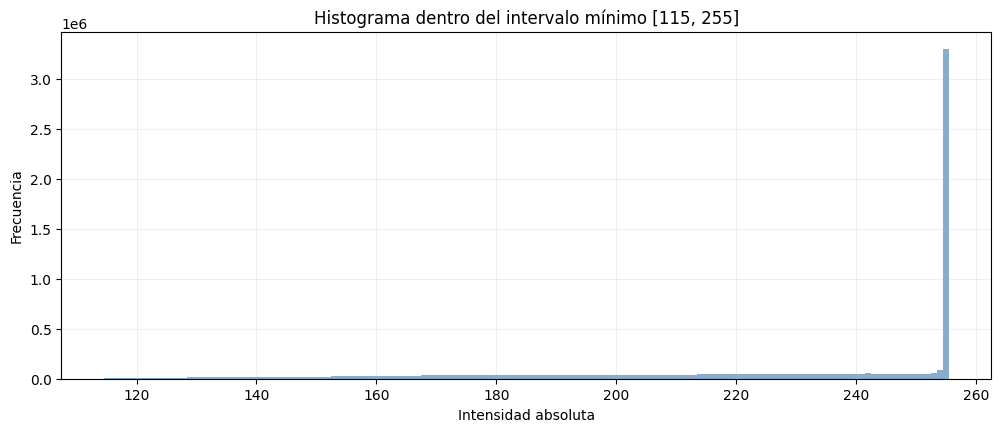

In [116]:
histograma_rango = histograma[r_min:r_max + 1].astype(float).copy()
longitud_rango = len(histograma_rango)
coordenadas_locales = np.arange(longitud_rango, dtype=float)
niveles_absolutos_rango = np.arange(r_min, r_max + 1)

print("Longitud del intervalo seleccionado:", longitud_rango)
print("Píxeles empíricos dentro del intervalo:", int(histograma_rango.sum()))
print("Porcentaje real conservado por el intervalo:", round(100 * histograma_rango.sum() / imagen.size, 5), "%")
print("Nota: los píxeles fuera del intervalo no se eliminan de la imagen.")

plt.figure(figsize=(12, 4.5))
plt.bar(niveles_absolutos_rango, histograma_rango, width=1.0, alpha=0.65, color="steelblue")
plt.title(f"Histograma dentro del intervalo mínimo [{r_min}, {r_max}]")
plt.xlabel("Intensidad absoluta")
plt.ylabel("Frecuencia")
plt.grid(alpha=0.2)
plt.show()

## 5. Aproximar el histograma dentro del intervalo seleccionado

In [117]:
METODO_APROXIMACION = "PCHIP"  # "PCHIP", "LINEAL" o "FOURIER"
NUM_PUNTOS = 250                # Para PCHIP o LINEAL
NUM_ARMONICOS = 12              # Para FOURIER

if longitud_rango == 1:
    puntos_x = np.array([0], dtype=int)
    puntos_y = histograma_rango.copy()
    histograma_aproximado = histograma_rango.copy()
    armonicos_efectivos = 0
    puntos_efectivos = 1
else:
    if METODO_APROXIMACION.upper() in ("PCHIP", "LINEAL"):
        puntos_efectivos = min(max(2, int(NUM_PUNTOS)), longitud_rango)
        puntos_x = np.unique(np.rint(np.linspace(0, longitud_rango - 1, puntos_efectivos)).astype(int))
        puntos_y = histograma_rango[puntos_x]
        if METODO_APROXIMACION.upper() == "PCHIP":
            interpolante = PchipInterpolator(puntos_x, puntos_y, extrapolate=False)
            histograma_aproximado = np.asarray(interpolante(coordenadas_locales), dtype=float)
        else:
            histograma_aproximado = np.interp(coordenadas_locales, puntos_x, puntos_y)
        armonicos_efectivos = 0
    elif METODO_APROXIMACION.upper() == "FOURIER":
        puntos_x = puntos_y = None
        puntos_efectivos = 0
        coeficientes = np.fft.rfft(histograma_rango)
        max_armonicos = len(coeficientes) - 1
        armonicos_efectivos = min(max(0, int(NUM_ARMONICOS)), max_armonicos)
        coeficientes_filtrados = np.zeros_like(coeficientes)
        coeficientes_filtrados[:armonicos_efectivos + 1] = coeficientes[:armonicos_efectivos + 1]
        histograma_aproximado = np.fft.irfft(coeficientes_filtrados, n=longitud_rango)
    else:
        raise ValueError("Método no válido. Usa PCHIP, LINEAL o FOURIER.")

print("Método:", METODO_APROXIMACION.upper())
print("Intervalo absoluto:", (r_min, r_max))
if puntos_x is not None and METODO_APROXIMACION.upper() != "FOURIER":
    print("Puntos de control efectivos:", len(puntos_x))
if METODO_APROXIMACION.upper() == "FOURIER":
    print("Armónicos efectivos:", armonicos_efectivos)
print("Error absoluto medio en el intervalo:", round(float(np.mean(np.abs(histograma_rango-histograma_aproximado))), 4))

Método: PCHIP
Intervalo absoluto: (115, 255)
Puntos de control efectivos: 141
Error absoluto medio en el intervalo: 0.0


## 6. Visualizar la aproximación sobre el histograma

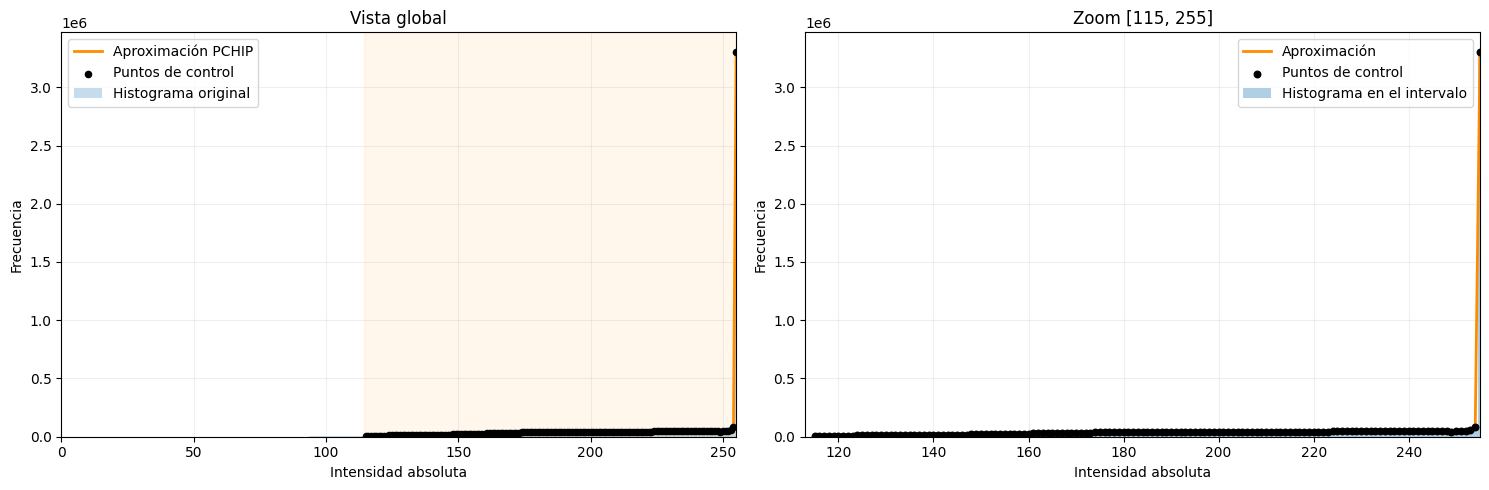

In [118]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
ejes[0].bar(niveles, histograma, width=1.0, alpha=0.25, label="Histograma original")
ejes[0].axvspan(r_min-0.5, r_max+0.5, color="orange", alpha=0.08)
ejes[0].plot(niveles_absolutos_rango, histograma_aproximado, color="darkorange", linewidth=2, label=f"Aproximación {METODO_APROXIMACION.upper()}")
if puntos_x is not None and METODO_APROXIMACION.upper() != "FOURIER" and len(puntos_x) > 1:
    ejes[0].scatter(r_min+puntos_x, puntos_y, color="black", s=20, label="Puntos de control", zorder=3)
ejes[0].set(title="Vista global", xlabel="Intensidad absoluta", ylabel="Frecuencia", xlim=(0,255))
ejes[0].grid(alpha=0.2)
ejes[0].legend()
ejes[1].bar(niveles_absolutos_rango, histograma_rango, width=1.0, alpha=0.35, label="Histograma en el intervalo")
ejes[1].plot(niveles_absolutos_rango, histograma_aproximado, color="darkorange", linewidth=2, label="Aproximación")
if puntos_x is not None and METODO_APROXIMACION.upper() != "FOURIER" and len(puntos_x) > 1:
    ejes[1].scatter(r_min+puntos_x, puntos_y, color="black", s=22, label="Puntos de control", zorder=3)
ejes[1].set(title=f"Zoom [{r_min}, {r_max}]", xlabel="Intensidad absoluta", ylabel="Frecuencia")
ejes[1].set_xlim(max(0,r_min-2), min(255,r_max+2))
ejes[1].grid(alpha=0.2)
ejes[1].legend()
plt.tight_layout()
plt.show()

## 7. Transformar la curva sobre el eje completo de intensidades

Se utilizan cuatro parámetros:

\[
G(r)=C\,\widehat h\!\left(\frac{r-r_{\min}-B}{A}\right)+D,\quad A>0.
\]

`A > 1` expande el intervalo transformado; `0 < A < 1` lo contrae. `B` desplaza la curva completa a izquierda o derecha. `C` escala verticalmente y `D` desplaza verticalmente dentro del soporte transformado. Fuera de ese soporte, la función se define como cero. Las frecuencias negativas se convierten en cero.

In [119]:

# %% CELDA 14 — CALCULAR A, B Y C AUTOMÁTICAMENTE

# ==========================================================
# 1. PARÁMETROS HORIZONTALES
# ==========================================================

# Rango dinámico como diferencia entre el extremo superior
# y el inferior del intervalo seleccionado.
rd = int(r_max - r_min)

if rd > 0:
    A = 255.0 / rd
else:
    A = 1.0

B = -float(r_min)
D = 0.0

# Número real de píxeles de la imagen.
N = int(imagen.size)

# ==========================================================
# 2. CONSTRUIR LA CURVA TRANSFORMADA SIN MULTIPLICAR POR C
# ==========================================================

niveles_float = np.arange(256, dtype=float)

# Coordenada de origen de cada intensidad de salida.
coordenada_fuente = (
    niveles_float - r_min - B
) / A

# La curva solo existe dentro de su soporte transformado.
soporte_transformado = (
    (coordenada_fuente >= 0)
    & (coordenada_fuente <= longitud_rango - 1)
)

# Evaluar la aproximación construida en la celda anterior.
valores_fuente = np.interp(
    coordenada_fuente,
    coordenadas_locales,
    histograma_aproximado,
    left=0.0,
    right=0.0
)

# Evitar frecuencias negativas.
base_transformada = np.zeros(256, dtype=float)

base_transformada[soporte_transformado] = np.maximum(
    valores_fuente[soporte_transformado],
    0.0
)

suma_base = float(base_transformada.sum())

if suma_base <= 0:
    raise ValueError(
        "La curva transformada tiene área cero. "
        "No es posible calcular C."
    )

# ==========================================================
# 3. COMPARAR LAS DOS FORMAS DE CALCULAR C
# ==========================================================

# C que iguala el área de la aproximación original.
area_aproximacion_original = float(
    np.maximum(histograma_aproximado, 0.0).sum()
)

C_area_aproximacion = (
    area_aproximacion_original / suma_base
)

# C que iguala el área discreta sin redondear al número
# total de píxeles de la imagen.
C_area_total_pixeles = N / suma_base

# ==========================================================
# 4. BUSCAR EL C MÍNIMO QUE ALCANZA TODOS LOS PÍXELES
#    DESPUÉS DEL REDONDEO A FRECUENCIAS ENTERAS
# ==========================================================

def calcular_frecuencias_para_C(c):
    return np.rint(
        c * base_transformada
    ).astype(np.int64)


def suma_frecuencias_para_C(c):
    return int(calcular_frecuencias_para_C(c).sum())


# Establecer un intervalo inicial para la búsqueda.
inferior = 0.0
superior = max(
    C_area_total_pixeles,
    np.finfo(float).tiny
)

# Asegurar que el extremo superior alcanza el total requerido.
while suma_frecuencias_para_C(superior) < N:
    superior *= 2.0

# Búsqueda binaria del umbral.
for _ in range(200):
    medio = inferior + (superior - inferior) / 2.0

    if medio == inferior or medio == superior:
        break

    if suma_frecuencias_para_C(medio) >= N:
        superior = medio
    else:
        inferior = medio

C = superior

# Refinar hasta encontrar el menor valor representable
# cuyo resultado alcanza N, según la regla de redondeo usada.
for _ in range(1000):
    anterior = np.nextafter(C, -np.inf)

    if anterior <= 0:
        break

    if suma_frecuencias_para_C(anterior) < N:
        break

    C = anterior

# ==========================================================
# 5. GENERAR LA FUNCIÓN Y EL HISTOGRAMA OBJETIVO DEFINITIVOS
# ==========================================================

funcion_transformada_bruta = np.zeros(256, dtype=float)

funcion_transformada_bruta[soporte_transformado] = (
    C * valores_fuente[soporte_transformado] + D
)

funcion_transformada = np.maximum(
    funcion_transformada_bruta,
    0.0
)

frecuencias_objetivo = np.rint(
    funcion_transformada
).astype(np.int64)

frecuencias_objetivo = np.maximum(
    frecuencias_objetivo,
    0
)

# ==========================================================
# 6. MOSTRAR RESULTADOS
# ==========================================================

suma_objetivo = int(frecuencias_objetivo.sum())

print("=" * 48)
print("RESULTADOS DEL CÁLCULO AUTOMÁTICO")
print("=" * 48)

print(f"Intervalo seleccionado: [{r_min}, {r_max}]")
print(f"Rango dinámico rd: {rd}")
print(f"A = 255 / rd: {A:.12f}")
print(f"B = -r_min: {B:.12f}")
print(f"C para igualar el área aproximada: {C_area_aproximacion:.12f}")
print(f"C para igualar el total de píxeles: {C_area_total_pixeles:.12f}")
print(f"C final tras considerar el redondeo: {C:.12f}")
print(f"D: {D:.6f}")

print("-" * 48)
print(f"Píxeles de la imagen: {N:,}")
print(f"Área de la aproximación original: {area_aproximacion_original:.4f}")
print(f"Área transformada sin C: {suma_base:.4f}")
print(f"Suma de frecuencias objetivo: {suma_objetivo:,}")
print(f"Diferencia objetivo - total: {suma_objetivo - N:,}")
print(f"Sobrantes que se enviarían a 255: {max(N - suma_objetivo, 0):,}")
print("=" * 48)

RESULTADOS DEL CÁLCULO AUTOMÁTICO
Intervalo seleccionado: [115, 255]
Rango dinámico rd: 140
A = 255 / rd: 1.821428571429
B = -r_min: -115.000000000000
C para igualar el área aproximada: 0.599238831874
C para igualar el total de píxeles: 0.608210544927
C final tras considerar el redondeo: 0.608210522336
D: 0.000000
------------------------------------------------
Píxeles de la imagen: 8,185,344
Área de la aproximación original: 8064602.0000
Área transformada sin C: 13458076.4314
Suma de frecuencias objetivo: 8,185,344
Diferencia objetivo - total: 0
Sobrantes que se enviarían a 255: 0


In [120]:

# Parámetros de la transformación; cambia uno cada vez.
#A = 255/rango_dinamico  # Debe ser > 0; A>1 amplía y 0<A<1 contrae.
#B = 0-r_min  # Desplazamiento horizontal en niveles absolutos.
#C = 1  # Escala vertical.
D = 0.0  # Desplazamiento vertical dentro del soporte transformado.

if A <= 0:
    raise ValueError("A debe ser mayor que cero.")

# Para cada intensidad de salida r, calcular la coordenada local de origen.
coordenada_fuente = (niveles.astype(float) - r_min - B) / A
soporte_transformado = (coordenada_fuente >= 0) & (coordenada_fuente <= longitud_rango - 1)
valores_fuente = np.interp(
    coordenada_fuente,
    coordenadas_locales,
    histograma_aproximado,
    left=0.0,
    right=0.0
)

# G(r) solo recibe D dentro del soporte transformado.
funcion_transformada_bruta = np.zeros(256, dtype=float)
funcion_transformada_bruta[soporte_transformado] = (
    C * valores_fuente[soporte_transformado] + D
)
funcion_transformada = np.maximum(funcion_transformada_bruta, 0.0)

# Usar directamente la función transformada como frecuencias objetivo.
frecuencias_objetivo = np.rint(funcion_transformada).astype(np.int64)
frecuencias_objetivo = np.maximum(frecuencias_objetivo, 0)

print(f"Parámetros: A={A}, B={B}, C={C}, D={D}")
print("Soporte transformado teórico:", (r_min + B, r_min + B + A*(longitud_rango-1)))
print("Suma de frecuencias objetivo:", int(frecuencias_objetivo.sum()))
print("Total de píxeles originales:", imagen.size)
print("Diferencia objetivo - total:", int(frecuencias_objetivo.sum()-imagen.size))

Parámetros: A=1.8214285714285714, B=-115.0, C=0.6082105223359467, D=0.0
Soporte transformado teórico: (0.0, 255.0)
Suma de frecuencias objetivo: 8185344
Total de píxeles originales: 8185344
Diferencia objetivo - total: 0


## 8. Ver la transformación y el histograma objetivo

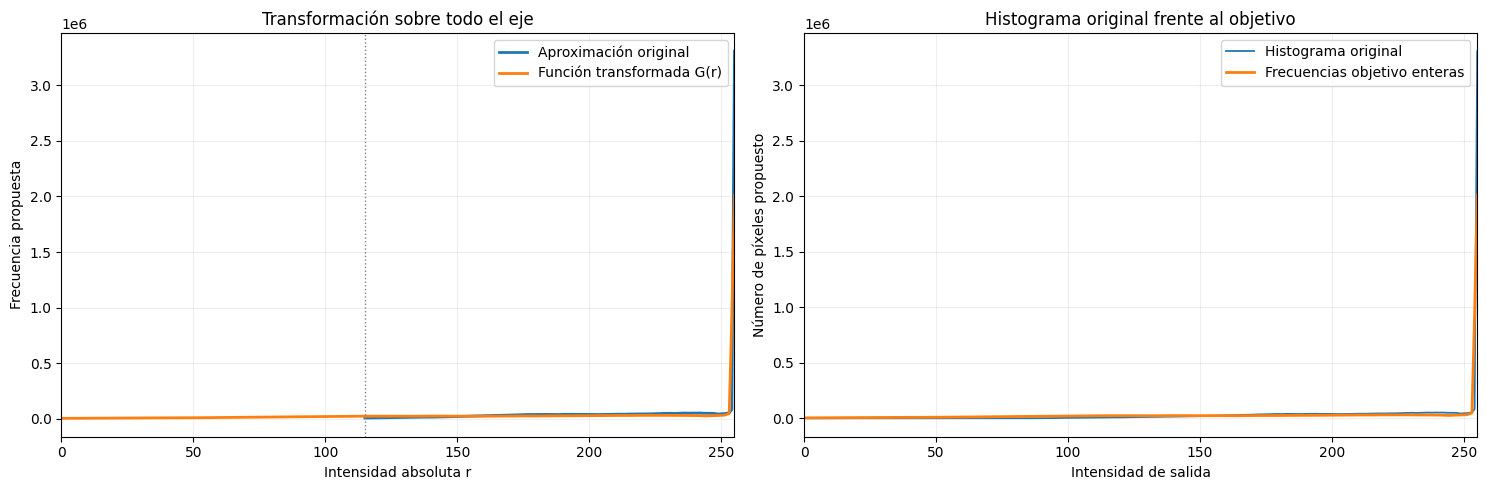

In [121]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
ejes[0].plot(niveles_absolutos_rango, histograma_aproximado, label="Aproximación original", linewidth=2)
ejes[0].plot(niveles, funcion_transformada, label="Función transformada G(r)", linewidth=2)
ejes[0].axvline(r_min, color="gray", linestyle=":", linewidth=1)
ejes[0].set(title="Transformación sobre todo el eje", xlabel="Intensidad absoluta r", ylabel="Frecuencia propuesta", xlim=(0,255))
ejes[0].grid(alpha=0.2)
ejes[0].legend()
ejes[1].plot(niveles, histograma, label="Histograma original", linewidth=1.3)
ejes[1].plot(niveles, frecuencias_objetivo, label="Frecuencias objetivo enteras", linewidth=2)
ejes[1].set(title="Histograma original frente al objetivo", xlabel="Intensidad de salida", ylabel="Número de píxeles propuesto", xlim=(0,255))
ejes[1].grid(alpha=0.2)
ejes[1].legend()
plt.tight_layout()
plt.show()

## 9. Reasignar los píxeles según su orden de intensidad original

In [122]:
def reasignar_pixeles_por_frecuencia(imagen_gris, frecuencias):
    original = np.asarray(imagen_gris, dtype=np.uint8)
    plano = original.ravel()
    total = plano.size
    frecuencias = np.maximum(np.asarray(frecuencias, dtype=np.int64).ravel(), 0)
    if frecuencias.size != 256:
        raise ValueError("Se requieren exactamente 256 frecuencias objetivo.")

    orden = np.argsort(plano, kind="stable")
    salida_plana = np.empty_like(plano)
    cursor = 0
    asignados_por_nivel = np.zeros(256, dtype=np.int64)
    for nivel in range(256):
        disponibles = total - cursor
        if disponibles <= 0:
            break
        cantidad = min(int(frecuencias[nivel]), disponibles)
        if cantidad > 0:
            indices = orden[cursor:cursor+cantidad]
            salida_plana[indices] = nivel
            asignados_por_nivel[nivel] += cantidad
            cursor += cantidad

    sobrantes = total - cursor
    if sobrantes > 0:
        salida_plana[orden[cursor:]] = 255
        asignados_por_nivel[255] += sobrantes

    salida = salida_plana.reshape(original.shape)
    histograma_logrado = np.bincount(salida.ravel(), minlength=256)
    return salida, histograma_logrado, asignados_por_nivel, int(sobrantes)

imagen_propuesta, histograma_logrado, asignados_por_nivel, sobrantes_255 = reasignar_pixeles_por_frecuencia(
    imagen, frecuencias_objetivo
)

print("Píxeles originales:", imagen.size)
print("Píxeles resultantes:", imagen_propuesta.size)
print("Sobrantes asignados a 255:", sobrantes_255)
print("Suma objetivo:", int(frecuencias_objetivo.sum()))
print("Suma histograma logrado:", int(histograma_logrado.sum()))
print("¿Se conserva el total de píxeles?:", imagen_propuesta.size == imagen.size)

Píxeles originales: 8185344
Píxeles resultantes: 8185344
Sobrantes asignados a 255: 0
Suma objetivo: 8185344
Suma histograma logrado: 8185344
¿Se conserva el total de píxeles?: True


## 10. Comparar frecuencias objetivo y resultado real

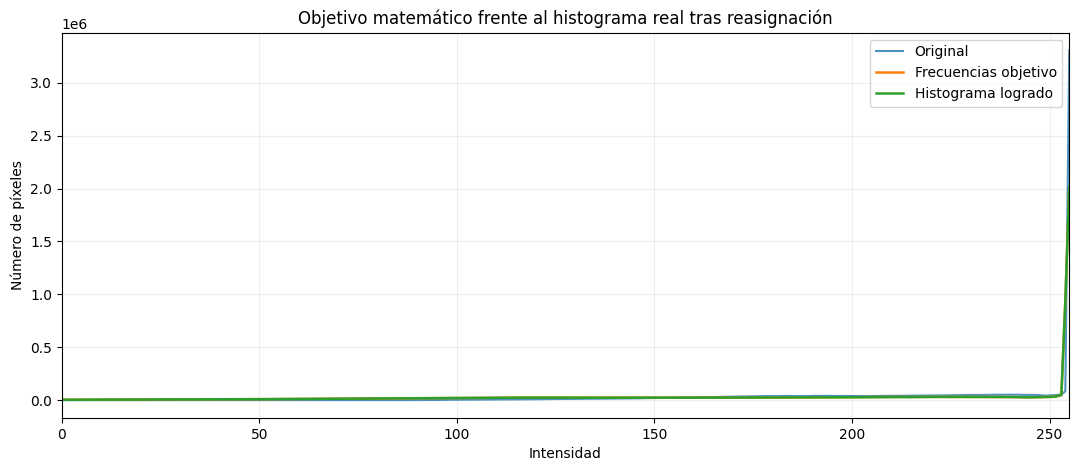

In [123]:
plt.figure(figsize=(13, 5))
plt.plot(niveles, histograma, label="Original", alpha=0.8)
plt.plot(niveles, frecuencias_objetivo, label="Frecuencias objetivo", linewidth=1.8)
plt.plot(niveles, histograma_logrado, label="Histograma logrado", linewidth=1.8)
plt.title("Objetivo matemático frente al histograma real tras reasignación")
plt.xlabel("Intensidad")
plt.ylabel("Número de píxeles")
plt.xlim(0,255)
plt.grid(alpha=0.2)
plt.legend()
plt.show()

## 11. Generar las referencias: ecualización clásica y CLAHE

In [124]:
imagen_he = cv2.equalizeHist(imagen)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
imagen_clahe = clahe.apply(imagen)
resultados = {
    "Original": imagen,
    "Modelo V3 intervalo mínimo": imagen_propuesta,
    "Ecualización clásica (HE)": imagen_he,
    "CLAHE": imagen_clahe,
}

## 12. Comparar histogramas y CDF de las imágenes

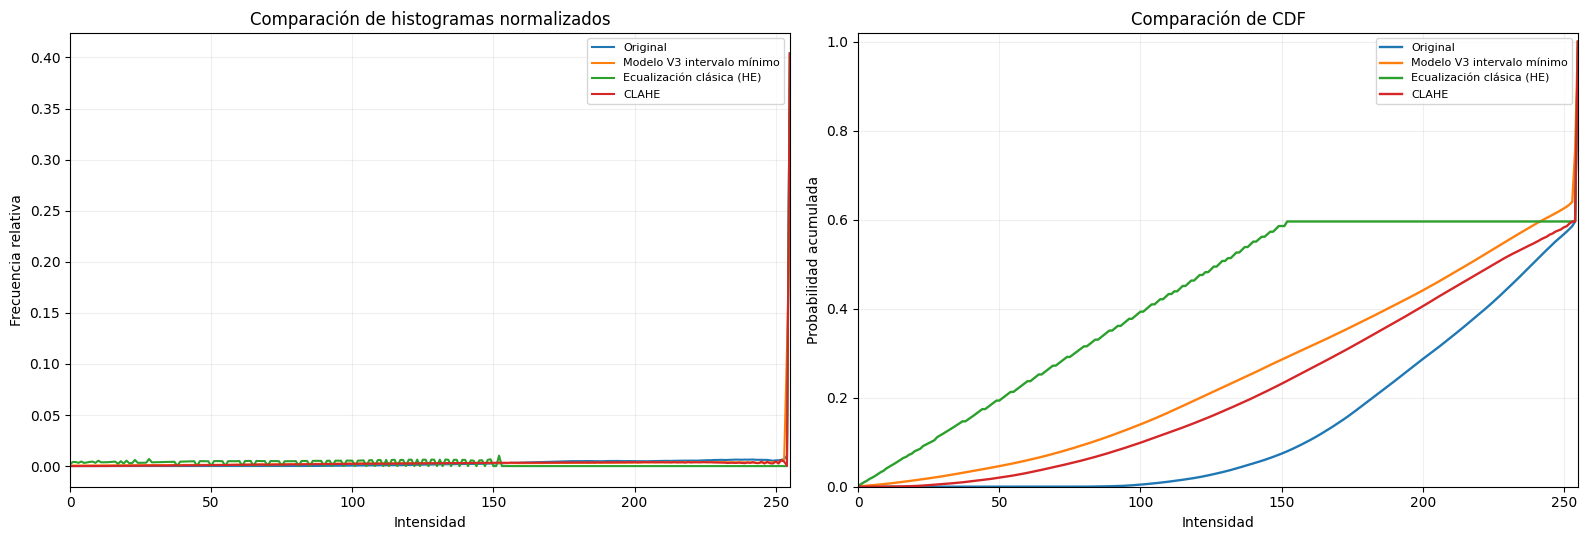

In [125]:
fig, ejes = plt.subplots(1, 2, figsize=(16, 5.5))
for nombre, img in resultados.items():
    hist = np.bincount(img.ravel(), minlength=256)
    ejes[0].plot(niveles, hist/img.size, label=nombre, linewidth=1.5)
    ejes[1].plot(niveles, np.cumsum(hist)/img.size, label=nombre, linewidth=1.7)
ejes[0].set(title="Comparación de histogramas normalizados", xlabel="Intensidad", ylabel="Frecuencia relativa", xlim=(0,255))
ejes[0].grid(alpha=0.2)
ejes[0].legend(fontsize=8)
ejes[1].set(title="Comparación de CDF", xlabel="Intensidad", ylabel="Probabilidad acumulada", xlim=(0,255), ylim=(0,1.02))
ejes[1].grid(alpha=0.2)
ejes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 13. Comparación visual de imágenes

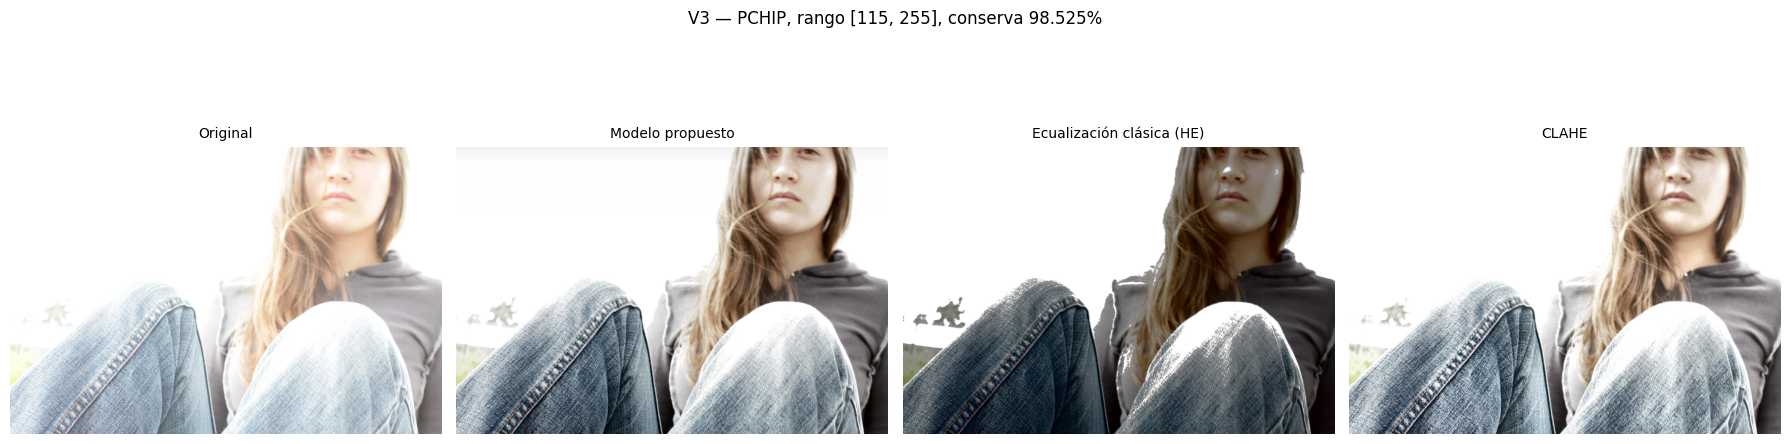

Imagen guardada: imagen_transformada_V3.png
Tipo de imagen: Color


In [126]:
# %% COMPARACIÓN VISUAL FINAL — CONSERVAR EL COLOR ORIGINAL

def conservar_color(imagen_intensidad):
    imagen_intensidad = np.asarray(
        imagen_intensidad,
        dtype=np.uint8
    )

    # Si la original es en escala de grises, no convertir a color.
    if not es_color:
        return imagen_intensidad

    # Convertir la imagen original de RGB a LAB.
    imagen_lab = cv2.cvtColor(
        imagen_rgb_original,
        cv2.COLOR_RGB2LAB
    )

    # Sustituir la luminosidad por la imagen generada por el modelo.
    imagen_lab[:, :, 0] = imagen_intensidad

    # Convertir de nuevo a RGB, conservando los canales cromáticos.
    return cv2.cvtColor(
        imagen_lab,
        cv2.COLOR_LAB2RGB
    )


# Preparar las cuatro imágenes.
resultados_visuales = {
    "Original": imagen_rgb_original if es_color else imagen,
    "Modelo propuesto": conservar_color(imagen_propuesta),
    "Ecualización clásica (HE)": conservar_color(imagen_he),
    "CLAHE": conservar_color(imagen_clahe)
}

# Mostrar la comparación.
fig, ejes = plt.subplots(1, 4, figsize=(18, 5.5))

for ax, (nombre, img) in zip(ejes, resultados_visuales.items()):
    if img.ndim == 2:
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    else:
        ax.imshow(img)

    ax.set_title(nombre, fontsize=10)
    ax.axis("off")

plt.suptitle(
    f"V3 — {METODO_APROXIMACION.upper()}, "
    f"rango [{r_min}, {r_max}], "
    f"conserva {porcentaje_real:.3f}%"
)

plt.tight_layout()
plt.show()

# Guardar el resultado visual del modelo.
Image.fromarray(
    resultados_visuales["Modelo propuesto"]
).save("imagen_transformada_V3.png")

print("Imagen guardada: imagen_transformada_V3.png")
print("Tipo de imagen:", "Color" if es_color else "Escala de grises")

## 14. Comparar métricas y guardar los resultados

In [127]:
tabla_metricas = pd.DataFrame({nombre: calcular_metricas(img) for nombre, img in resultados.items()}).T
display(tabla_metricas.round(4))

Image.fromarray(imagen_propuesta).save("imagen_transformada_histograma_V3.png")
tabla_metricas.to_csv("metricas_comparacion_histograma_V3.csv", encoding="utf-8-sig")

aproximacion_completa = np.zeros(256, dtype=float)
aproximacion_completa[r_min:r_max+1] = histograma_aproximado
pd.DataFrame({
    "intensidad": niveles,
    "histograma_original": histograma.astype(int),
    "intervalo_minimo": ((niveles >= r_min) & (niveles <= r_max)).astype(int),
    "aproximacion_histograma": aproximacion_completa,
    "funcion_transformada_bruta": funcion_transformada_bruta,
    "funcion_transformada_no_negativa": funcion_transformada,
    "frecuencia_objetivo": frecuencias_objetivo,
    "histograma_logrado": histograma_logrado,
}).to_csv("frecuencias_histograma_V3.csv", index=False, encoding="utf-8-sig")

print("Archivos guardados:")
print("- imagen_transformada_histograma_V3.png")
print("- metricas_comparacion_histograma_V3.csv")
print("- frecuencias_histograma_V3.csv")

,Media,Desviación estándar,Mínimo,Máximo,Rango dinámico,Rango P1-P99,Entropía (bits),Píxeles en 0 (%),Píxeles en 255 (%)
Original,221.2399,40.5510,73.0,255.0,182.0,146.0,5.2040,0.0000,40.3938
Modelo V3 intervalo mínimo,191.3344,70.1254,0.0,255.0,255.0,240.0,6.2900,0.0538,24.5679
Ecualización clásica (HE),148.6528,93.9264,0.0,255.0,255.0,252.0,5.0751,0.1759,40.3938
CLAHE,200.6194,63.1506,7.0,255.0,248.0,217.0,5.5754,0.0000,40.3938


Archivos guardados:
- imagen_transformada_histograma_V3.png
- metricas_comparacion_histograma_V3.csv
- frecuencias_histograma_V3.csv


In [128]:
# %% DESCARGA OPCIONAL DE LA IMAGEN RESULTANTE

respuesta = input(
    "¿Deseas descargar la imagen resultante del modelo? Escribe Y o N: "
).strip().upper()

if respuesta == "Y":

    # Utilizar la imagen del modelo conservando el color original.
    imagen_descargar = resultados_visuales["Modelo propuesto"]

    nombre_archivo = "imagen_transformada_V3.png"

    # Guardar la imagen como PNG.
    Image.fromarray(imagen_descargar).save(nombre_archivo)

    # Descargar automáticamente si se está utilizando Google Colab.
    try:
        from google.colab import files
        files.download(nombre_archivo)
        print("Descarga iniciada:", nombre_archivo)

    except ImportError:
        print(f"Imagen guardada localmente como: {nombre_archivo}")

elif respuesta == "N":
    print("No se descargó ninguna imagen.")

else:
    print("Respuesta no válida. Escribe Y para descargar o N para omitir.")

¿Deseas descargar la imagen resultante del modelo? Escribe Y o N: N
No se descargó ninguna imagen.


## Lectura de resultados y precauciones

1. El intervalo es el de menor amplitud que contiene al menos el porcentaje solicitado. Si hay empate, se selecciona el que contiene más píxeles; si persiste, el que comienza en menor intensidad.
2. El porcentaje se calcula usando el histograma empírico, no el área de la aproximación. Debido a que las intensidades son discretas, el porcentaje real puede superar el solicitado.
3. El intervalo sirve para definir la función que se aproxima. No se eliminan los píxeles que quedan fuera; todos participan en la reasignación posterior.
4. `A > 1` amplía el soporte horizontal, mientras que `0 < A < 1` lo contrae. `B` desplaza la curva sobre el eje 0–255. Fuera del soporte transformado, la frecuencia propuesta es cero.
5. Los valores negativos de la función transformada se convierten en cero. Las frecuencias objetivo se redondean a enteros y no se normalizan para forzar una suma igual al número de píxeles.
6. Si los píxeles disponibles se agotan antes de completar el objetivo, la asignación se detiene. Si quedan píxeles al recorrer todo el objetivo, se asignan a 255.
7. El intervalo de menor amplitud optimiza el criterio de porcentaje, no garantiza por sí mismo preservar todos los detalles semánticos de la imagen. Conviene probar varios porcentajes en distintas imágenes.